# 02 — Explore how the context changes over time

**Stage:** exploratory analysis. Produces Figure 1 and Tables 1–2 of the paper.

The project asks whether a model trained on 2008 still works after the Euribor collapse. Before modelling, this notebook shows *how much* the context changes between the periods: the interest rate, the share of clients who subscribe, and the mix of clients who are called.

In [1]:
import sys
from pathlib import Path

# Make the shared module in src/ importable from this notebook
sys.path.append(str(Path.cwd().parent))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from src.data_utils import load_processed, PERIODS, FIGURES_DIR, RESULTS_DIR

df = load_processed()
FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

## 1. Monthly series

In [3]:
monthly = (df.groupby("year_month")
             .agg(calls=("y", "size"),
                  yes_rate=("y", lambda s: (s == "yes").mean()),
                  euribor=("euribor3m", "mean"))
             .reset_index())
monthly["date"] = pd.to_datetime(monthly["year_month"])

# Add the months with no calls as empty rows, so the lines in Figure 1
# break at those gaps instead of joining across them.
all_months = pd.date_range(monthly["date"].min(), monthly["date"].max(), freq="MS")
monthly = monthly.set_index("date").reindex(all_months).rename_axis("date").reset_index()
print("Months with no calls:", [d.strftime("%Y-%m") for d in monthly.loc[monthly["calls"].isna(), "date"]])
monthly.head(6)

Months with no calls: ['2008-09', '2009-01', '2009-02', '2010-01', '2010-02']


,date,year_month,calls,yes_rate,euribor
0,2008-05-01,2008-05,7763.0,0.030916,4.857663
1,2008-06-01,2008-06,4374.0,0.042981,4.931639
2,2008-07-01,2008-07,6685.0,0.060883,4.961587
3,2008-08-01,2008-08,5175.0,0.052367,4.964804
4,2008-09-01,NaN,NaN,NaN,NaN
5,2008-10-01,2008-10,67.0,0.626866,4.923776


## 2. Figure 1: Euribor rate and subscription rate over time

Two panels sharing the same time axis (one scale per panel, so neither measure is distorted). The shaded bands mark the four periods. Months with fewer than 100 calls are drawn as hollow points, because their subscription rate is very noisy. The lines break at months with no calls.

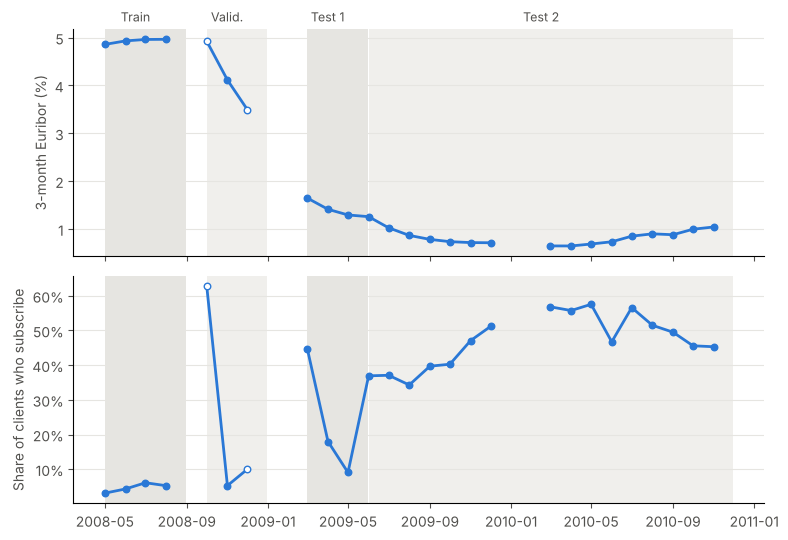

In [4]:
BLUE = "#2a78d6"
INK, MUTED = "#0b0b0b", "#52514e"
BAND = {"train": "#e6e5e1", "validation": "#f0efec",
        "test_1": "#e6e5e1", "test_2": "#f0efec"}

fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
small = monthly["calls"] < 100
full = monthly["calls"] >= 100

for ax, col, label in [(axes[0], "euribor", "3-month Euribor (%)"),
                       (axes[1], "yes_rate", "Share of clients who subscribe")]:
    # Shade the four periods
    for name, (start, end) in PERIODS.items():
        x0 = pd.Timestamp(start)
        x1 = pd.Timestamp(end) + pd.offsets.MonthEnd(0)
        ax.axvspan(x0, x1, color=BAND[name], zorder=0, lw=0)
    ax.plot(monthly["date"], monthly[col], color=BLUE, lw=2, zorder=2)
    ax.scatter(monthly.loc[full, "date"], monthly.loc[full, col],
               s=22, color=BLUE, zorder=3)
    ax.scatter(monthly.loc[small, "date"], monthly.loc[small, col],
               s=22, facecolor="white", edgecolor=BLUE, zorder=3)
    ax.set_ylabel(label, color=MUTED)
    ax.grid(axis="y", color="#e6e5e1", lw=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)

axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

# Period names above the top panel
labels = {"train": "Train", "validation": "Valid.",
          "test_1": "Test 1", "test_2": "Test 2"}
for name, (start, end) in PERIODS.items():
    mid = pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2
    axes[0].text(mid, 1.02, labels[name], transform=axes[0].get_xaxis_transform(),
                 ha="center", va="bottom", fontsize=9, color=MUTED)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig1_context_over_time.pdf")
fig.savefig(FIGURES_DIR / "fig1_context_over_time.png", dpi=200)
plt.show()

**Reading Figure 1.**

- **Training (May–Aug 2008):** the Euribor is flat, close to 4.9%, and only 3–6% of clients subscribe each month.
- **Validation (Oct–Dec 2008):** the rate starts to fall, from about 5% to 3.5%. The 63% subscription rate in October comes from only 67 calls; November, with 3,616 calls, stays at 5%.
- **Test 1 (Mar–May 2009):** the rate is now between 1.2% and 1.8%. The subscription rate is higher (9–45%) and varies a lot from month to month.
- **Test 2 (Jun 2009–Nov 2010):** the rate stays below 1.3% and the subscription rate climbs to 34–58%, about ten times its training level, while far fewer calls are made each month.

So the test periods differ from training in two ways at once: the economic context (the Euribor) and how often clients say yes.

## 3. Table 1: the four periods

For each period: the number of calls, the subscription rate, the range of the Euribor rate, and the share of clients already contacted in a previous campaign.

In [5]:
order = list(PERIODS)
table1 = (df.groupby("period")
            .agg(calls=("y", "size"),
                 yes_rate=("y", lambda s: (s == "yes").mean()),
                 euribor_min=("euribor3m", "min"),
                 euribor_max=("euribor3m", "max"),
                 previously_contacted=("previous", lambda s: (s > 0).mean()))
            .loc[order])
table1.to_csv(RESULTS_DIR / "table1_periods.csv")
table1.round(3)

,calls,yes_rate,euribor_min,euribor_max,previously_contacted
period,,,,,
train,23997,0.046,4.855,4.970,0.000
validation,3693,0.063,3.053,5.045,0.199
test_1,8534,0.128,1.244,1.811,0.300
test_2,4964,0.445,0.634,1.286,0.469


**Key point for the models.** In both test periods the Euribor rate lies entirely **below** anything seen in training (about 4.9%). A model cannot learn from the training data what happens at such low rates: a random forest will treat a rate of 0.7% like the lowest rate it has seen, while a logistic regression will extend its straight-line trend. This is one reason the two models may degrade differently.

In [6]:
train_min = df.loc[df["period"] == "train", "euribor3m"].min()
for p in ["test_1", "test_2"]:
    share_below = (df.loc[df["period"] == p, "euribor3m"] < train_min).mean()
    print(f"{p}: {share_below:.0%} of calls have a Euribor below the training minimum ({train_min})")

test_1: 100% of calls have a Euribor below the training minimum (4.855)
test_2: 100% of calls have a Euribor below the training minimum (4.855)


The problem is wider than the level of the rate. **Inside the training period, the economic context barely moves:** the Euribor stays between 4.86% and 4.97%, and the other macro-economic columns take only two to four different values. The table below shows this. With so little variation, the models have almost no information to learn how these columns affect subscriptions, yet they are exactly the columns that change the most afterwards.

In [7]:
from src.data_utils import MACRO_COLUMNS

train = df[df["period"] == "train"]
macro_train = train[MACRO_COLUMNS].agg(["min", "max", "nunique"]).T
macro_train.columns = ["train_min", "train_max", "distinct_values_in_train"]
macro_train

,train_min,train_max,distinct_values_in_train
emp.var.rate,1.100,1.400,2.0
cons.price.idx,93.444,94.465,4.0
cons.conf.idx,-42.700,-36.100,4.0
euribor3m,4.855,4.970,25.0
nr.employed,5191.000,5228.100,2.0


## 4. Does the mix of clients change too?

Besides the economy, the bank may have called different kinds of clients over time. We compare a few client characteristics across periods.

In [8]:
mix = (df.groupby("period")
         .agg(mean_age=("age", "mean"),
              share_cellular=("contact", lambda s: (s == "cellular").mean()),
              share_students_retired=("job", lambda s: s.isin(["student", "retired"]).mean()),
              mean_contacts_this_campaign=("campaign", "mean"))
         .loc[order])
mix.to_csv(RESULTS_DIR / "table2_client_mix.csv")
mix.round(3)

,mean_age,share_cellular,share_students_retired,mean_contacts_this_campaign
period,,,,
train,40.125,0.447,0.037,2.939
validation,40.653,0.881,0.025,1.893
test_1,38.075,0.926,0.057,2.244
test_2,42.421,0.859,0.225,1.831


**Interpretation.** The clients who are called change a lot between the periods, not only the economic context.

- **Previous contacts change the most.** In the training period *no* client had been contacted in an earlier campaign (`previous` is always 0 and `poutcome` is always `nonexistent`). The share rises to 20% in validation, 30% in test 1 and 47% in test 2, where `poutcome = success` appears for over 1,100 calls. A model trained on 2008 therefore cannot learn anything from these two columns: they are constant in its training data, while they matter in the test periods (in test 2, 52% of previously contacted clients subscribe, against 38% of the others).
- **The contact channel flips.** Only 45% of the training calls go to a mobile phone, against 86–93% afterwards. The model learns the effect of `contact` mostly from landline calls, which become a small minority later.
- **The client profile shifts in test 2.** The share of students and retired clients rises from about 4% in training to 22% in test 2, and the mean age goes up from 40 to 42. These groups subscribe more often than the others in every period, so a larger share of test 2 comes from groups that were rare in the training data.
- **Fewer calls per client.** The mean number of contacts in the current campaign falls from 2.9 in training to about 1.8–2.2 afterwards.

**Consequence for a model trained on 2008.** Together with the much higher subscription rate (5% in training, 45% in test 2) and the Euribor values below the training range, this means the test periods differ from training in both the inputs (covariate shift) and the base rate (prior shift). We should expect the predicted probabilities to be badly calibrated after the crisis, even if the ranking of clients (ROC-AUC) holds up better. A flexible model such as a random forest has no data to rely on for the new combinations (previously contacted clients, rates far below the training range), so it may degrade more than a logistic regression; this is what the next notebooks test.